In [3]:
import copy
from pathlib import Path
 
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import matplotlib.pyplot as plt
from torch.utils.data import DataLoader, TensorDataset
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, roc_auc_score, average_precision_score)
 
from model import build_model
# SESUAIKAN nama modul ini dengan file tempat fungsi/konstanta tersebut didefinisikan
from dataset import prepare_client_data, TARGET, DROP_COLS
 
# ============================================================
# 1. KONFIGURASI
# ============================================================
CLIENT_DIR = Path(r'C:\Users\s2\Documents\FIXRKI\bfprssprep\split\clients')
 
DEVICE     = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
EPOCHS     = 50
BATCH_SIZE = 64
LR         = 1e-3
PATIENCE   = 5
SEED       = 42
 
METRIK = ['acc', 'prec', 'rec', 'f1', 'auc', 'prauc']
NAMA   = {'acc': 'Akurasi', 'prec': 'Presisi', 'rec': 'Recall',
          'f1': 'F1-score', 'auc': 'AUC', 'prauc': 'PR-AUC'}
SPLITS = ['val', 'test']
 
torch.manual_seed(SEED)
np.random.seed(SEED)
print("Device:", DEVICE)
 
# %%
# ============================================================
# 2. MUAT DATA SEMUA CLIENT (scaling + konversi ke tensor)
# ============================================================
clients, scaler, feature_names = prepare_client_data(CLIENT_DIR)
 
print(f"Jumlah client : {len(clients)}")
print(f"Daftar state  : {list(clients.keys())}")
print(f"Target        : {TARGET}")
print(f"Kolom dibuang : {DROP_COLS}")
 
 
def get_xy(st, split):
    """Ambil tensor (X, y) milik client `st` untuk split train/val/test.
    Asumsi key: X_{split}_t dan y_{split}_t (sesuai y_*_t yang dipakai di bawah)."""
    c = clients[st]
    return c[f'X_{split}_t'], c[f'y_{split}_t']
 

Device: cuda
Jumlah client : 44
Daftar state  : [1, 2, 4, 5, 8, 10, 11, 12, 13, 15, 16, 17, 18, 19, 20, 22, 23, 24, 25, 26, 27, 29, 30, 31, 33, 34, 35, 36, 37, 38, 39, 40, 41, 44, 45, 46, 48, 49, 50, 51, 53, 54, 55, 56]
Target        : _michd
Kolom dibuang : ['iyear', '_state', 'cvdinfr4', 'cvdcrhd4']


state_1 | ep 11 | VAL f1 0.5230 prauc 0.4966 | TEST f1 0.4524 prauc 0.4300
state_2 | ep 11 | VAL f1 0.4583 prauc 0.3929 | TEST f1 0.4299 prauc 0.3895
state_4 | ep 08 | VAL f1 0.4554 prauc 0.4356 | TEST f1 0.4505 prauc 0.4938
state_5 | ep 09 | VAL f1 0.5464 prauc 0.5427 | TEST f1 0.5296 prauc 0.4593
state_8 | ep 09 | VAL f1 0.4286 prauc 0.3441 | TEST f1 0.3851 prauc 0.3050
state_10 | ep 10 | VAL f1 0.4659 prauc 0.4364 | TEST f1 0.4542 prauc 0.3696
state_11 | ep 15 | VAL f1 0.4167 prauc 0.4541 | TEST f1 0.4211 prauc 0.4296
state_12 | ep 08 | VAL f1 0.4418 prauc 0.4019 | TEST f1 0.4910 prauc 0.4426
state_13 | ep 08 | VAL f1 0.5235 prauc 0.4719 | TEST f1 0.5646 prauc 0.5130
state_15 | ep 08 | VAL f1 0.4036 prauc 0.3554 | TEST f1 0.3760 prauc 0.3582
state_16 | ep 11 | VAL f1 0.4725 prauc 0.5277 | TEST f1 0.3906 prauc 0.4624
state_17 | ep 11 | VAL f1 0.5078 prauc 0.4398 | TEST f1 0.4493 prauc 0.4361
state_18 | ep 10 | VAL f1 0.5140 prauc 0.4515 | TEST f1 0.4328 prauc 0.4695
state_19 | ep 09 

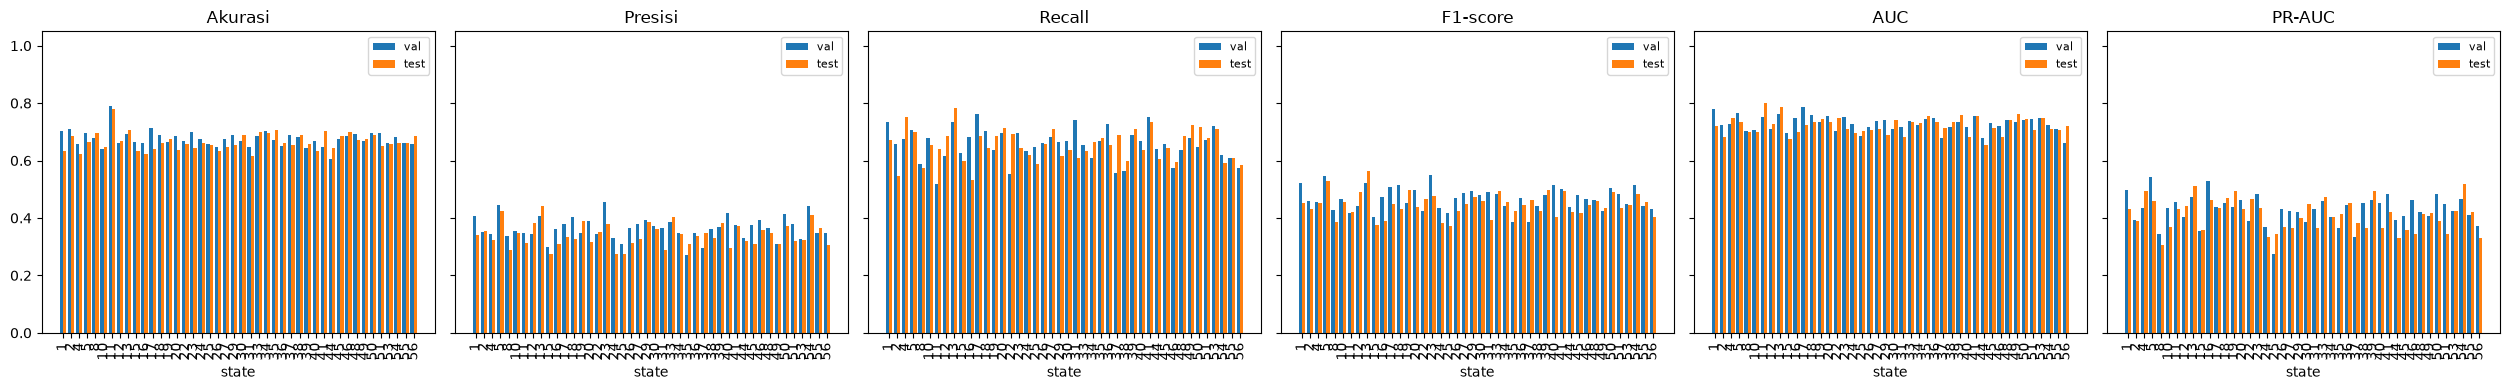


==================== RANKING STATE — VAL (urut F1) ====================
       rank_f1  rata2_rank     acc    prec     rec      f1     auc   prauc  prauc_lift  n_val  pos_val  pos_rate_val%  n_train  pos_rate_train%
state                                                                                                                                          
23           1        5.17  0.6999  0.4543  0.6970  0.5501  0.7527  0.4845        1.84   1003      264          26.32     1763            25.01
5            2        4.00  0.6958  0.4449  0.7078  0.5464  0.7650  0.5427        2.10    595      154          25.88     1076            25.93
13           3        5.67  0.6935  0.4062  0.7358  0.5235  0.7626  0.4719        2.06    695      159          22.88     1605            21.31
1            4        4.00  0.7046  0.4062  0.7339  0.5230  0.7812  0.4966        2.25    562      124          22.06      979            24.11
54           5       15.67  0.6824  0.4413  0.6185  0.5151  0.7

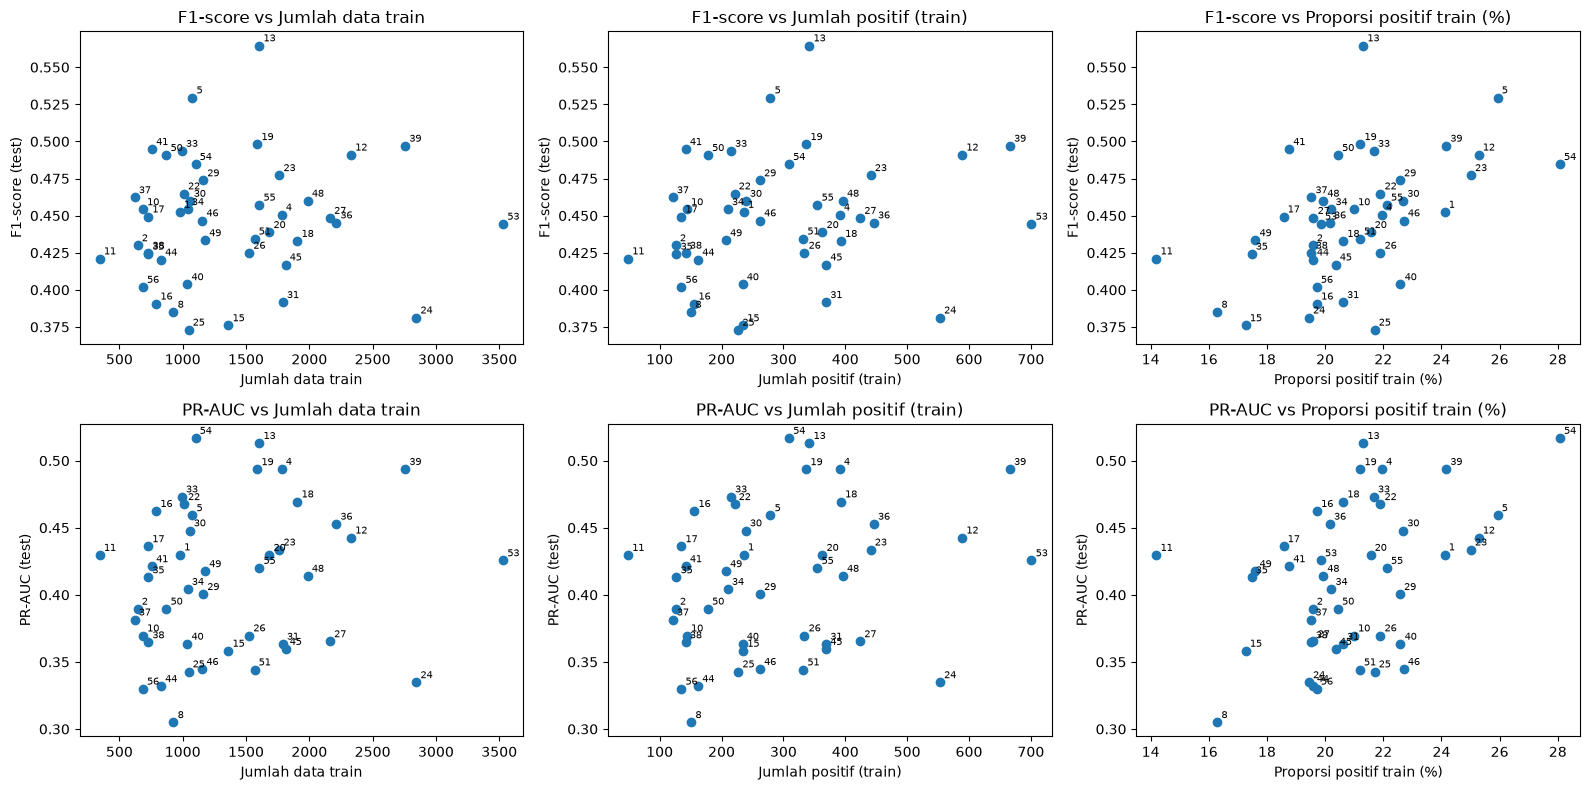

In [4]:

# %%
# ============================================================
# 3. FUNGSI TRAIN & EVALUASI (+ PR-AUC)
# ============================================================
def make_loader(X, y, shuffle):
    ds = TensorDataset(X.float(), y.long())
    g = torch.Generator().manual_seed(SEED)       # shuffle reproducible
    return DataLoader(ds, batch_size=BATCH_SIZE, shuffle=shuffle, generator=g)
 
 
@torch.no_grad()
def predict_logits(model, X, bs=4096):
    """Inferensi per-batch agar aman untuk data besar."""
    model.eval()
    out = [model(X[i:i + bs].float().to(DEVICE)) for i in range(0, len(X), bs)]
    return torch.cat(out)
 
 
@torch.no_grad()
def evaluate(model, X, y, criterion=None):
    """Kembalikan dict metrik: acc, prec, rec, f1, auc, prauc (+ loss)."""
    logits = predict_logits(model, X)
    prob = torch.softmax(logits, dim=1)[:, 1].cpu().numpy()
    pred = logits.argmax(dim=1).cpu().numpy()
    y_np = y.long().cpu().numpy()
    dua_kelas = len(np.unique(y_np)) > 1
 
    out = {
        'acc':    accuracy_score(y_np, pred),
        'prec':   precision_score(y_np, pred, zero_division=0),
        'rec':    recall_score(y_np, pred, zero_division=0),
        'f1':     f1_score(y_np, pred, zero_division=0),
        # AUC & PR-AUC tidak bermakna jika y hanya satu kelas
        'auc':    roc_auc_score(y_np, prob) if dua_kelas else np.nan,
        'prauc':  average_precision_score(y_np, prob) if dua_kelas else np.nan,
    }
    if criterion is not None:
        out['loss'] = criterion(logits, y.long().to(DEVICE)).item()
    return out
 
 
def train_local(X_train, y_train, X_val, y_val, verbose=False):
    """Latih satu model lokal; kembalikan (model terbaik, history)."""
    model = build_model(in_dim=X_train.shape[1], seed=SEED).to(DEVICE)
 
    n_pos = int(y_train.sum())
    n_neg = len(y_train) - n_pos
    if n_pos > 0 and n_neg > 0:
        w = torch.tensor([len(y_train) / (2 * n_neg),
                          len(y_train) / (2 * n_pos)], dtype=torch.float32)
    else:
        w = torch.ones(2)
    criterion = nn.CrossEntropyLoss(weight=w.to(DEVICE))
    optimizer = torch.optim.Adam(model.parameters(), lr=LR)
 
    loader = make_loader(X_train, y_train, shuffle=True)
 
    best_loss, best_state, wait = float('inf'), None, 0
    history = []
 
    for epoch in range(1, EPOCHS + 1):
        model.train()
        running = 0.0
        for xb, yb in loader:
            xb, yb = xb.to(DEVICE), yb.to(DEVICE)
            optimizer.zero_grad()
            loss = criterion(model(xb), yb)
            loss.backward()
            optimizer.step()
            running += loss.item() * len(xb)
        train_loss = running / len(loader.dataset)
 
        # val loss memakai criterion berbobot yang sama dengan train
        val = evaluate(model, X_val, y_val, criterion)
        history.append({'epoch': epoch, 'train_loss': train_loss,
                        'val_loss': val['loss'], 'val_f1': val['f1'],
                        'val_prauc': val['prauc']})
        if verbose:
            print(f"  ep {epoch:02d} | train {train_loss:.4f} | "
                  f"val {val['loss']:.4f} | val_f1 {val['f1']:.4f} | "
                  f"val_prauc {val['prauc']:.4f}")
 
        if val['loss'] < best_loss - 1e-5:
            best_loss, wait = val['loss'], 0
            best_state = copy.deepcopy(model.state_dict())
        else:
            wait += 1
            if wait >= PATIENCE:
                break
 
    # fallback: jika tidak pernah ada perbaikan (mis. loss NaN), pakai bobot terakhir
    if best_state is not None:
        model.load_state_dict(best_state)
    return model, pd.DataFrame(history)
 
 
# %%
# ============================================================
# 4. LATIH SEMUA CLIENT + EVALUASI DI VAL DAN TEST
# ============================================================
local_models, local_hist = {}, {}
rows = {s: [] for s in SPLITS}
 
for st in clients:
    X_tr, y_tr = get_xy(st, 'train')
    X_va, y_va = get_xy(st, 'val')
    X_te, y_te = get_xy(st, 'test')
 
    model, hist = train_local(X_tr, y_tr, X_va, y_va)
    res = {'val': evaluate(model, X_va, y_va),
           'test': evaluate(model, X_te, y_te)}
 
    local_models[st] = model
    local_hist[st]   = hist
    for s in SPLITS:
        rows[s].append({'state': st, 'epochs_run': len(hist), **res[s]})
 
    # {st} tanpa :02d supaya aman bila key state berupa string
    print(f"state_{st} | ep {len(hist):02d} | "
          f"VAL f1 {res['val']['f1']:.4f} prauc {res['val']['prauc']:.4f} | "
          f"TEST f1 {res['test']['f1']:.4f} prauc {res['test']['prauc']:.4f}")
 
hasil_val  = pd.DataFrame(rows['val']).set_index('state')
hasil_test = pd.DataFrame(rows['test']).set_index('state')
hasil_lokal = hasil_test                      # kompatibel dengan kode lama
HASIL = {'val': hasil_val, 'test': hasil_test}
 
for s in SPLITS:
    print(f"\n=== Hasil {s.upper()} tiap client (model lokal) ===")
    print(HASIL[s].round(4).to_string())
    print(f"\nRata-rata {s.upper()}:\n",
          HASIL[s].drop(columns='epochs_run').mean().round(4))
 
# %%
# ============================================================
# 5. RINGKASAN METRIK (VAL vs TEST) + PR-AUC
# ============================================================
def n_split(split):
    return pd.Series({st: len(clients[st][f'y_{split}_t']) for st in clients})
 
 
def ringkas_metrik(split):
    h = HASIL[split][METRIK]
    n = n_split(split).reindex(h.index)
    # rata-rata berbobot: bobot dinormalisasi ulang per metrik (NaN diabaikan)
    berbobot = {}
    for m in METRIK:
        ok = h[m].notna()
        berbobot[m] = np.average(h.loc[ok, m], weights=n[ok]) if ok.any() else np.nan
    return pd.DataFrame({
        'Rata-rata (makro)':  h.mean(),
        'Std antar client':   h.std(),
        'Rata-rata berbobot': pd.Series(berbobot),
        'Min':                h.min(),
        'Max':                h.max(),
    }).rename(index=NAMA)
 
 
ringkasan = {s: ringkas_metrik(s) for s in SPLITS}
for s in SPLITS:
    print(f"=== Ringkasan antar client: {s.upper()} ===")
    print(ringkasan[s].round(4).to_string(), "\n")
 
# Perbandingan val vs test (rata-rata makro) + gap (indikasi overfit ke val)
banding = pd.DataFrame({
    'VAL':  hasil_val[METRIK].mean(),
    'TEST': hasil_test[METRIK].mean(),
}).rename(index=NAMA)
banding['Gap (val-test)'] = banding['VAL'] - banding['TEST']
print("=== Perbandingan rata-rata makro VAL vs TEST ===")
print(banding.round(4).to_string())
 
# Visualisasi: bar berdampingan val vs test per state
states = hasil_val.index.astype(str)
x = np.arange(len(states))
lebar = 0.4
fig, axes = plt.subplots(1, len(METRIK), figsize=(4.2 * len(METRIK), 4), sharey=True)
for ax, m in zip(axes, METRIK):
    ax.bar(x - lebar / 2, hasil_val[m],  lebar, label='val')
    ax.bar(x + lebar / 2, hasil_test[m], lebar, label='test')
    ax.set_title(NAMA[m])
    ax.set_xticks(x)
    ax.set_xticklabels(states, rotation=90)
    ax.set_xlabel('state')
    ax.set_ylim(0, 1.05)
    ax.legend(fontsize=8)
plt.tight_layout()
plt.show()
 
# %%
# ============================================================
# 6. RANKING STATE (VAL & TEST) + INFO DATA + PR-AUC
# ============================================================
info = pd.DataFrame({
    st: {
        'n_train':   len(c['y_train_t']),
        'n_val':     len(c['y_val_t']),
        'n_test':    len(c['y_test_t']),
        'pos_train': int(c['y_train_t'].sum()),
        'pos_val':   int(c['y_val_t'].sum()),
        'pos_test':  int(c['y_test_t'].sum()),
    }
    for st, c in clients.items()
}).T
info['pos_rate_train%'] = (100 * info['pos_train'] / info['n_train']).round(2)
info['pos_rate_val%']   = (100 * info['pos_val']   / info['n_val']).round(2)
info['pos_rate_test%']  = (100 * info['pos_test']  / info['n_test']).round(2)
info.index.name = 'state'
 
 
def ranking(split, N=5):
    g = HASIL[split][METRIK].join(info)
 
    # Ranking utama: F1, tie-breaker PR-AUC (NaN PR-AUC dianggap terendah).
    # Dibuat lewat sort agar tidak bergantung pada rank() atas tuple (rapuh).
    urut = g.sort_values(['f1', 'prauc'], ascending=False, na_position='last').index
    g['rank_f1'] = pd.Series(np.arange(1, len(g) + 1), index=urut).reindex(g.index)
    g['rata2_rank'] = g[METRIK].rank(ascending=False, method='min').mean(axis=1).round(2)
 
    # Lift PR-AUC thd baseline (baseline PR-AUC acak = proporsi positif)
    base = (g[f'pos_rate_{split}%'] / 100).replace(0, np.nan)   # hindari bagi nol
    g['prauc_lift'] = (g['prauc'] / base).round(2)
    g = g.sort_values(['rank_f1', 'rata2_rank'])
 
    kolom = (['rank_f1', 'rata2_rank'] + METRIK + ['prauc_lift',
             f'n_{split}', f'pos_{split}', f'pos_rate_{split}%', 'n_train',
             'pos_rate_train%'])
    n = min(N, len(g))
    print(f"\n{'=' * 20} RANKING STATE — {split.upper()} (urut F1) {'=' * 20}")
    print(g[kolom].round(4).to_string())
    print(f"\n--- {n} TERBAIK ({split.upper()}) ---")
    print(g[kolom].head(n).round(4).to_string())
    print(f"\n--- {n} TERENDAH ({split.upper()}) ---")
    print(g[kolom].tail(n).round(4).to_string())
 
    profil = pd.DataFrame({
        f'Top {n}':    g.head(n)[['n_train', f'n_{split}', 'pos_rate_train%']].mean(),
        f'Bottom {n}': g.tail(n)[['n_train', f'n_{split}', 'pos_rate_train%']].mean(),
        'Semua state': g[['n_train', f'n_{split}', 'pos_rate_train%']].mean(),
    }).round(2)
    print(f"\n--- PROFIL DATA ({split.upper()}): atas vs bawah ---")
    print(profil.to_string())
 
    kor = g[['n_train', 'pos_train', 'pos_rate_train%',
             'f1', 'rec', 'auc', 'prauc']].corr(method='spearman')
    print(f"\n--- KORELASI SPEARMAN data vs kinerja ({split.upper()}) ---")
    print(kor.loc[['n_train', 'pos_train', 'pos_rate_train%'],
                  ['f1', 'rec', 'auc', 'prauc']].round(3).to_string())
    return g
 
 
gabung_val  = ranking('val')
gabung_test = ranking('test')
 
# Konsistensi ranking val vs test (Spearman antar urutan state)
rk = pd.DataFrame({'rank_val': gabung_val['rank_f1'],
                   'rank_test': gabung_test['rank_f1']})
print("\nKorelasi ranking F1 val vs test (Spearman):",
      round(rk.corr(method='spearman').iloc[0, 1], 3))
 
# Visualisasi: F1 dan PR-AUC (test) vs ukuran/proporsi data
g = gabung_test
fig, axes = plt.subplots(2, 3, figsize=(16, 8))
for r, met in enumerate(['f1', 'prauc']):
    for ax, xcol, judul in zip(axes[r],
                               ['n_train', 'pos_train', 'pos_rate_train%'],
                               ['Jumlah data train', 'Jumlah positif (train)',
                                'Proporsi positif train (%)']):
        ax.scatter(g[xcol], g[met])
        for st, row in g.iterrows():
            ax.annotate(str(st), (row[xcol], row[met]), fontsize=7,
                        xytext=(3, 3), textcoords='offset points')
        ax.set_xlabel(judul)
        ax.set_ylabel(f'{NAMA[met]} (test)')
        ax.set_title(f'{NAMA[met]} vs {judul}')
plt.tight_layout()
plt.show()
 
# Simpan (opsional)
# hasil_val.to_csv(CLIENT_DIR.parent / 'metrik_val.csv')
# hasil_test.to_csv(CLIENT_DIR.parent / 'metrik_test.csv')